In [2]:
import tarfile

file_path = "twenty+newsgroups/20_newsgroups.tar.gz"

with tarfile.open(file_path, "r:gz") as tar:
    tar.extractall("output_folder")

In [1]:
import os
import numpy as np
from sentence_transformers  import SentenceTransformer
import faiss
import pickle
import matplotlib.pyplot as plt


/Users/Shared/dummy/trademark/venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
dataset="output_folder/20_newsgroups"



In [4]:
import re

def clean_text(text):

    # remove email headers
    text = re.sub(r"From:.*\n", "", text)
    text = re.sub(r"Subject:.*\n", "", text)
    text = re.sub(r"Organization:.*\n", "", text)

    # remove quoted replies
    text = re.sub(r">.*\n", "", text)

    # remove urls
    text = re.sub(r"http\S+", "", text)

    # remove emails
    text = re.sub(r"\S+@\S+", "", text)

    # remove special characters
    text = re.sub(r"[^a-zA-Z0-9\s]", " ", text)

    # normalize spaces
    text = re.sub(r"\s+", " ", text)

    return text.strip()

In [6]:
metadata=[]
doc=[]
for collections in os.listdir(dataset):
    for file in os.listdir(os.path.join(dataset,collections)):
        with open(dataset+'/'+collections+'/'+file,"r",encoding='latin1') as f:
            text=clean_text(f.read())
            doc.append(text)
            metadata.append(
                {
                    "topic":collections,
                    "text":text
                }
            )
            
    

In [53]:
len(doc)

19997

In [ ]:
with open('data/doc_mapping.plk','wb')as f:
    pickle.dump(doc,f)

In [9]:
model=SentenceTransformer("all-MiniLM-L6-v2")


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 7931.07it/s]
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [10]:

embedding=model.encode(doc,convert_to_numpy=True,show_progress_bar=True)

Batches: 100%|██████████| 625/625 [03:09<00:00,  3.31it/s]


In [11]:
model.save("models/minilm")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  4.46it/s]


In [12]:
embedding.shape

(19997, 384)

In [16]:
print(embedding.dtype)

float32


In [47]:
index=faiss.tIPIndexFla(embedding.shape[1])
index.add(embedding.astype("float32"))

print("index count",index.ntotal)

index count 19997


In [48]:
query = doc[10]

query_emb=model.encode([query]).astype('float32')

distance, ind=index.search(query_emb,6)

print(distance)
print(ind)

[[1.         0.87934124 0.7619479  0.7597849  0.7054486  0.6823386 ]]
[[ 10 657 877 730  88 783]]


In [20]:
doc[657]

'Xref cantaloupe srv cs cmu edu soc culture turkish 33840 soc culture greek 21800 talk politics soviet 23509 talk politics mideast 76157 Newsgroups soc culture turkish soc culture greek talk politics soviet talk politics mideast Path cantaloupe srv cs cmu edu das news harvard edu noc near net uunet think com urartu sdpa org dbd Message ID effective Greek Armenian postings Date Fri 16 Apr 1993 22 54 09 GMT Lines 36 In article wrote KAAN Who the hell is this guy David Davidian I think he talks too much I am your alter ego KAAN Yo DAVID you would better shut the f up O K No its not OK What are you going to do Come and get me KAAN I don t like your attitute You are full of lies and shit In the United States we refer to it as Freedom of Speech If you don t like what I write either prove me wrong shut up or simply fade away KAAN Didn t you hear the saying DON T MESS WITH A TURC No Why do you ask What are you going to do Are you going to submit me to bodily harm Are you going to kill me Are y

In [21]:
doc[10]

'Xref cantaloupe srv cs cmu edu soc culture turkish 33729 soc culture greek 21760 talk politics soviet 23460 talk politics mideast 76089 Path cantaloupe srv cs cmu edu das news harvard edu noc near net howland reston ans net gatech prism gt1091a Newsgroups soc culture turkish soc culture greek talk politics soviet talk politics mideast Keywords effective Greek Armenian postings Message ID 16 Apr 93 18 11 11 GMT References soc culture turkish Lines 21 Who the hell is this guy David Davidian I think he talks too much Yo DAVID you would better shut the f up O K I don t like your attitute You are full of lies and shit Didn t you hear the saying DON T MESS WITH A TURC See ya in hell Timucin KAAN TIMUCIN Georgia Institute of Technology Atlanta Georgia 30332 uucp decvax hplabs ncar purdue rutgers gatech prism gt1091a Internet'

In [50]:
faiss.write_index(index, "data/news_index.faiss")

In [24]:
from sklearn.metrics.pairwise import cosine_similarity

In [25]:
cosine_similarity(embedding[10].reshape(1, -1),embedding[657].reshape(1, -1))

array([[0.87934136]], dtype=float32)

K:1, bic_scores:-26191034.236768294 
K:2, bic_scores:-26569424.570199046 
K:3, bic_scores:-26810216.9036298 
K:4, bic_scores:-27007465.237060547 
K:5, bic_scores:-27178901.5704913 
K:6, bic_scores:-27280525.90392205 
K:7, bic_scores:-27349958.237352803 
K:8, bic_scores:-27451226.570783556 
K:9, bic_scores:-27540134.904214308 
K:10, bic_scores:-27609321.23764506 
K:11, bic_scores:-27658639.571075812 
K:12, bic_scores:-27734149.904506564 
K:13, bic_scores:-27781862.237937316 
K:14, bic_scores:-27824164.57136807 
K:15, bic_scores:-27848966.90479882 
K:16, bic_scores:-27889939.23822957 
K:17, bic_scores:-27897065.57166032 
K:18, bic_scores:-27927963.905091073 
K:19, bic_scores:-27940768.238521826 
K:20, bic_scores:-27960312.571952578 
K:21, bic_scores:-27993760.90538333 
K:22, bic_scores:-28008641.238814082 
K:23, bic_scores:-28078497.572244834 
K:24, bic_scores:-28088959.905675586 
K:25, bic_scores:-28118498.23910634 
K:26, bic_scores:-28123434.57253709 
K:27, bic_scores:-28149096.9059678

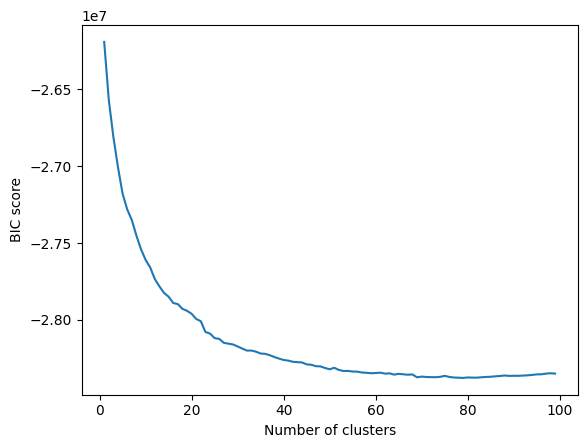

In [36]:
import matplotlib.pyplot as plt

bic_scores = []

for k in range(1, 100):

    gmm = GaussianMixture(n_components=k, covariance_type="diag",random_state=42)
    gmm.fit(embedding)
    v=gmm.bic(embedding)
    bic_scores.append(v)
    print(f'K:{k}, bic_scores:{v} ')

plt.plot(range(1,100), bic_scores)
plt.xlabel("Number of clusters")
plt.ylabel("BIC score")
print("best no of cluster K :",np.argmin(bic_scores)+1)

In [37]:
from sklearn.mixture import GaussianMixture

gmm = GaussianMixture(n_components=79, covariance_type="diag",random_state=42)

gmm.fit(embedding)


,n_components,79
,covariance_type,'diag'
,tol,0.001
,reg_covar,1e-06
,max_iter,100
,n_init,1
,init_params,'kmeans'
,weights_init,None
,means_init,None
,precisions_init,None
,random_state,42


In [52]:
with open("data/gmm_model.pkl", "wb") as f:
    pickle.dump(gmm, f)

In [38]:

prob=gmm.predict_proba(embedding)


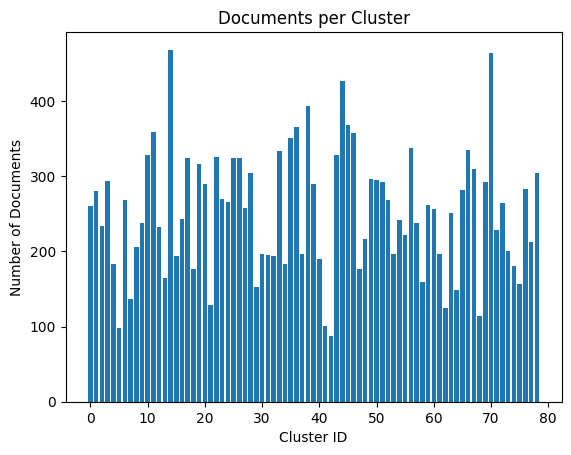

In [39]:

import numpy as np
import matplotlib.pyplot as plt

clusters = np.argmax(prob, axis=1)

unique, counts = np.unique(clusters, return_counts=True)

plt.bar(unique, counts)

plt.xlabel("Cluster ID")
plt.ylabel("Number of Documents")
plt.title("Documents per Cluster")

plt.show()

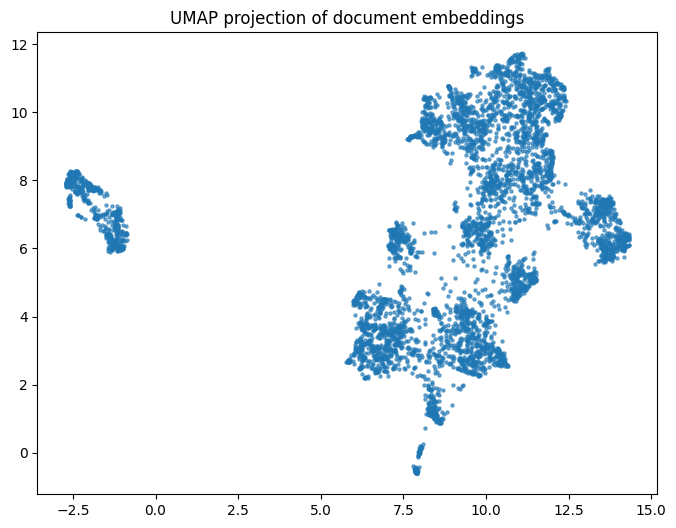

In [40]:

os.environ["OMP_NUM_THREADS"] = "1"

import numpy as np
import umap
import matplotlib.pyplot as plt

subset = np.random.choice(len(embedding), 5000, replace=False)
embedding_subset = embedding[subset]

reducer = umap.UMAP(
    n_neighbors=15,
    min_dist=0.1,
    metric="cosine",
    n_jobs=1
)

embedding_2d = reducer.fit_transform(embedding_subset)

plt.figure(figsize=(8,6))
plt.scatter(
    embedding_2d[:,0],
    embedding_2d[:,1],
    s=5,
    alpha=0.6
)

plt.title("UMAP projection of document embeddings")
plt.show()

In [41]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=5000
)

X = vectorizer.fit_transform(doc)

terms = vectorizer.get_feature_names_out()

In [42]:
import numpy as np

k = prob.shape[1]

for cluster_id in range(k):

    doc_ids = np.where(clusters == cluster_id)[0]

    if len(doc_ids) == 0:
        continue

    cluster_matrix = X[doc_ids]

    mean_tfidf = np.asarray(cluster_matrix.mean(axis=0)).flatten()

    top_words = mean_tfidf.argsort()[-10:][::-1]

    keywords = [terms[i] for i in top_words]

    print(f"\nCluster {cluster_id}")
    print(", ".join(keywords))


Cluster 0
crypt, key, edu, sci, security, pgp, cmu, des, encryption, alt

Cluster 1
christian, rutgers, edu, religion, church, soc, igor, approved, cmu, cs

Cluster 2
rutgers, edu, christian, religion, soc, cmu, alt, talk, approved, igor

Cluster 3
baseball, edu, sport, rec, net, cmu, news, cs, srv, com

Cluster 4
edu, sys, comp, hardware, mac, problem, cmu, monitor, mouse, pc

Cluster 5
font, fonts, windows, edu, comp, ms, os, cmu, net, misc

Cluster 6
forsale, misc, computers, edu, cmu, pc, sale, clone, mac, sys

Cluster 7
culture, soc, turkish, mideast, politics, talk, arabic, edu, pakistan, greek

Cluster 8
edu, motorcycles, rec, cmu, dod, autos, cs, state, duke, car

Cluster 9
edu, misc, talk, politics, cmu, alt, cs, legal, state, srv

Cluster 10
hockey, edu, sport, rec, cmu, ca, cs, net, news, srv

Cluster 11
graphics, edu, comp, image, cmu, gif, format, files, windows, cs

Cluster 12
politics, guns, edu, talk, cmu, alt, state, constitution, ohio, cs

Cluster 13
clipper, key, ch

In [56]:
uncertainty = prob.max(axis=1)

boundary_docs = np.argsort(uncertainty)[:10]
boundary_docs 

array([13883,  4099, 19637, 14292, 15713,  3315, 18788,  4378,  9317,
       17952])

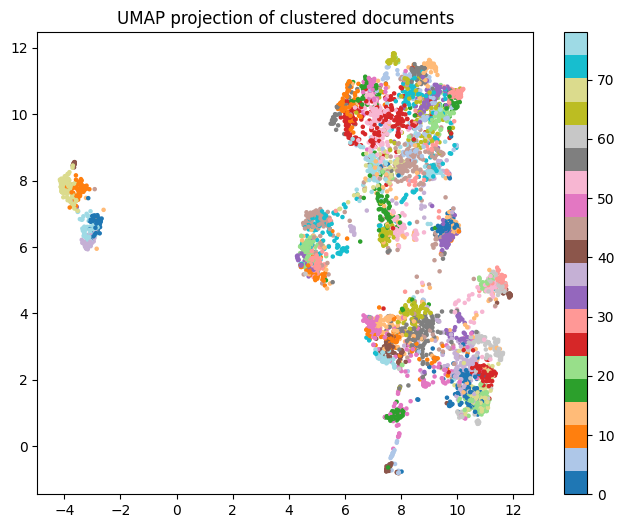

In [44]:
import numpy as np

subset = np.random.choice(len(embedding), 5000, replace=False)

embedding_subset = embedding[subset]
clusters_subset = clusters[subset]

embedding_2d = reducer.fit_transform(embedding_subset)

plt.figure(figsize=(8,6))

plt.scatter(
    embedding_2d[:,0],
    embedding_2d[:,1],
    c=clusters_subset,
    cmap="tab20",
    s=5
)
plt.colorbar()

plt.title("UMAP projection of clustered documents")

plt.show()